# KNN

### 데이터 불러오기

In [67]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

# 얼굴 데이터 다운로드
faces = fetch_olivetti_faces(data_home="./datasets")

### 데이터 Shape 조회


In [68]:
print("사진 묶음 크기:", faces.images.shape)
print("정답 묶음 크기:", faces.target.shape)
print("64x64=4096", faces.data.shape)
# np.unique()
print("사람 종류:", np.unique(faces.target))

사진 묶음 크기: (400, 64, 64)
정답 묶음 크기: (400,)
64x64=4096 (400, 4096)
사람 종류: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39]


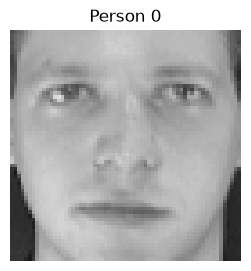

In [69]:
plt.figure(figsize=(3,3))

# 0번째 사진 출력
plt.imshow(faces.images[0], cmap="grey", vmin=0, vmax=1)
plt.title(f"Person {faces.target[0]}")
plt.axis("off")
plt.show()

In [70]:
corner = faces.images[0][20 : 28, 20 : 28]

print("가장 어두운 값:",corner.min())
print("가장 밝은 값:",corner.max())

가장 어두운 값: 0.5371901
가장 밝은 값: 0.71900827


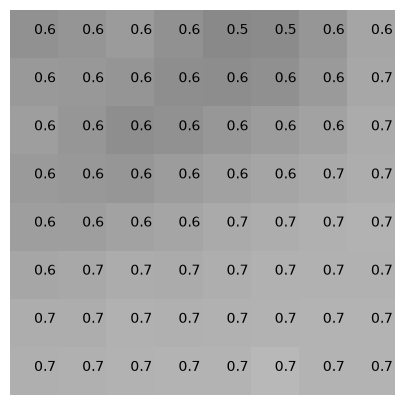

In [71]:
fig, ax = plt.subplots(figsize=(5,5))
ax.imshow(corner, cmap="grey", vmin=0, vmax=1)

plt.axis("off")
for r in range(8):
    for c in range(8):
        # r번째 행, c번째 열
        v = corner[r,c]
        ax.text(c,r, f"{v:.1f}")
plt.show()

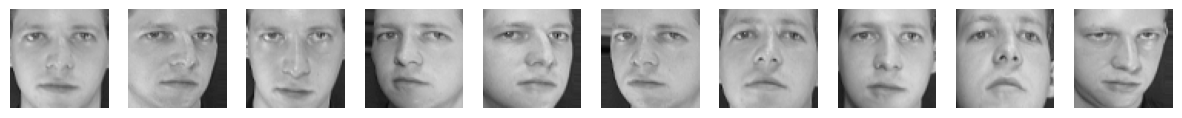

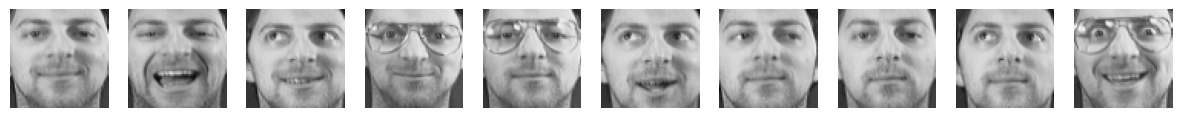

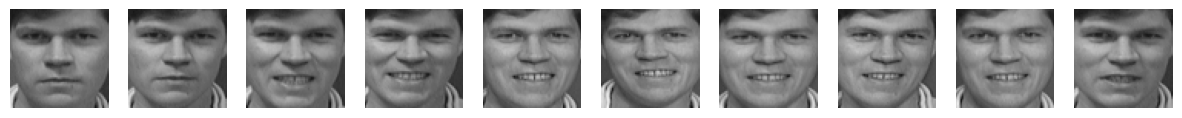

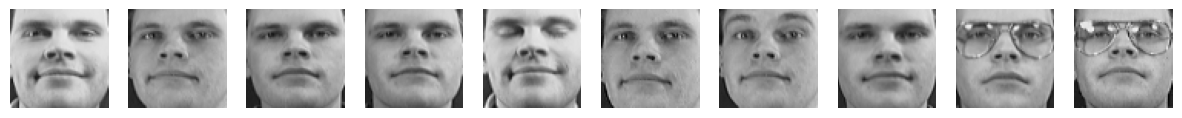

In [72]:
def show_person(person):
    pics = faces.images[faces.target == person]

    fig, axes = plt.subplots(1,10, figsize=(15,2))
    for ax, img in zip(axes, pics):
        ax.imshow(img, cmap = "grey", vmin = 0, vmax = 1)
        ax.axis("off")

    plt.show()

show_person(0)
show_person(6)
show_person(32)
show_person(35)

### Faces.images

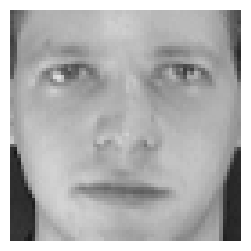

In [73]:
faces.images.shape
plt.figure(figsize=(3,3))
plt.imshow(faces.images[0], cmap="grey", vmin=0, vmax=1)
plt.axis("off")
plt.show()

In [74]:
faces.images[0].shape


(64, 64)

### 40명 사진 출력

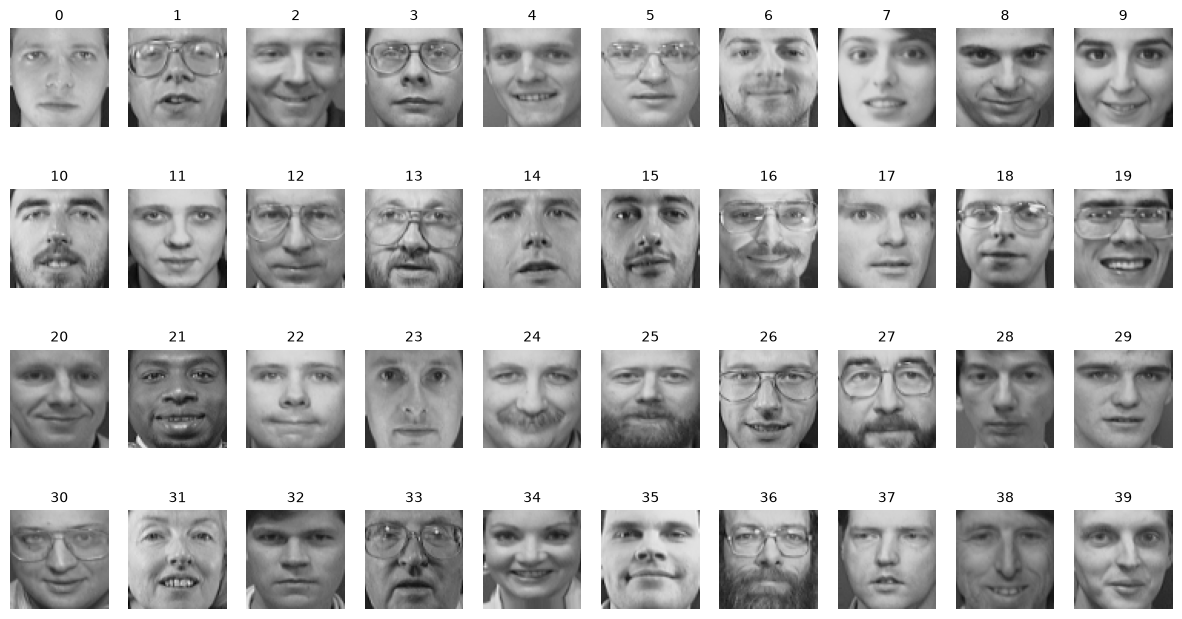

In [75]:
# 4 * 10 칸 배치
fig, axes = plt.subplots(4, 10, figsize=(15,8))

# axes.flat은 4 * 10으로 한 데이터를 한줄로 세우기 위함
for person, ax in enumerate(axes.flat):
    first = faces.images[faces.target == person][0]
    ax.imshow(first,cmap="grey",vmin=0,vmax=1)
    ax.set_title(person, fontsize=10)
    ax.axis("off")

plt.show()

### KNN 학습 및 예측
- KNN (K-Nearest Neighoods) -> 가장 가까운 이웃 뽑기

In [76]:
# KNN 학습
import numpy as np
from sklearn.datasets import fetch_olivetti_faces
from sklearn.neighbors import KNeighborsClassifier

# 섞이지 않은 원본(0번 ~ 10번, ...... 39번 10장)
faces = fetch_olivetti_faces(data_home="./datasets")

X = faces.data          # (400, 4096) 한장의 사진(64 * 64) 펼친 데이터
y = faces.target        # (400,) 정답 : 몇번째 사람인가? Index

print("X:",X.shape)
print("y:",y.shape)

X: (400, 4096)
y: (400,)


### 검증용(테스트용) 사진 선택
- 229번째 사진
- 몇번째 사람인가?

In [81]:
new_index = 229
new_photo = X[new_index]

known = np.arange(400) != new_index
known[229]

# X[known] 이 True인 339장 사진, 전달
X_known, y_known = X[known], y[known]

# 인접한 이웃수
K = 5
# KNN 객체 생성 및 생성
model = KNeighborsClassifier(n_neighbors=K)
model.fit(X_known, y_known)

# 가장 가까운 이웃 K개 찾기
dist, idx = model.kneighbors([new_photo], n_neighbors=K)

# 가장 가까운 인물
# [17 22 22 22 17]
print("가장 가까운 이웃:", y_known[idx[0]])

# 이웃과의 거리
print("이웃과의 거리:", dist[0].round(2))

# 예측한 사람
pred = model.predict([new_photo])
print("예측한 사람:", pred[0])

# 실제 정답
print("실제 정답:", y[new_index])

가장 가까운 이웃: [17 22 22 22 17]
이웃과의 거리: [6.07 6.26 6.44 6.63 6.68]
예측한 사람: 22
실제 정답: 22


### 시각화

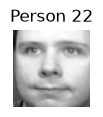

In [78]:
# 정답인 사람 229번째 사진이 몇번째 사람인지 [0...39]

plt.figure(figsize=(1,1))
plt.imshow(new_photo.reshape(64,64), cmap="grey")
plt.axis("off")
plt.title(f"Person {y[new_index]}")
plt.show()

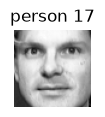

In [79]:
j = idx[0][0] # [17 22 22 22 17]

plt.figure(figsize=(1,1))
plt.imshow(X_known[j].reshape(64,64), cmap="grey")
plt.title(f"person {y_known[j]}")
plt.axis("off")
plt.show()

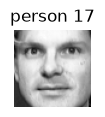

In [ ]:
for i in range(K):
    j = idx[0][i] # [17 22 22 22 17]

    plt.figure(figsize=(1,1))
    plt.imshow(X_known[j].reshape(64,64), cmap="grey")
    plt.title(f"person {y_known[j]}")
    plt.axis("off")

### 모델 평가

In [87]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# 전체 사진을 학습용과 테스트용으로 분리
X_train, X_test, y_train, y_test = train_test_split(
    faces.data,         # 사진데이터 : 각 사진을 한 줄로 펼친 값(400, 4096)
    faces.target,       # 정답데이터 : 각 사진의 사람 번호(0....39)
    test_size=0.25,      # 전체 사진 중 25%를 테스트용으로 분리
    random_state=42,
    stratify=faces.target  # 각 사람의 사진 비율을 비슷하게 유지
)

K = 5
model = KNeighborsClassifier(n_neighbors=K)
model.fit(X_train, y_train)

# 모델이 처음보는 테스트 사진으로 정확도 평가
accuracy = model.score(X_test, y_test)

print(f"예측 정확도: {accuracy:.2%}")

예측 정확도: 87.00%
